In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score)
import xgboost as xgb
import optuna

print('Libraries are ready')

Libraries are ready


In [2]:
gap_df = pd.read_csv('inequality_gap_sex.csv')
df_full = pd.read_csv('who_data_cleaned.csv')

if 'indicator_scale' not in gap_df.columns or 'whoreg6' not in gap_df.columns:
    try:
        df_full = pd.read_csv('who_data_cleaned.csv')
    except Exception:
        df_full = pd.read_excel('WHO Dataset.xlsx', sheet_name='Data')
    scale_map = df_full[['indicator_abbr', 'indicator_scale']].drop_duplicates('indicator_abbr')
    region_map = df_full[['iso3', 'whoreg6']].drop_duplicates('iso3')
    merged = gap_df.merge(scale_map, on='indicator_abbr', how='left').merge(region_map, on='iso3', how='left')
else:
    merged = gap_df.copy()

print("Merged shape:", merged.shape)
print("Missing indicator_scale:", merged['indicator_scale'].isnull().sum())
print("Missing whoreg6:", merged['whoreg6'].isnull().sum())

Merged shape: (476806, 14)
Missing indicator_scale: 0
Missing whoreg6: 2665


#### Converting the Continuous Gap into Low/Medium/High

In [3]:
low_cut = 0.90
med_cut = 4.20

merged['abs_gap'] = merged['inequality_gap'].abs()
merged['risk_category'] = pd.cut(
    merged['abs_gap'],
    bins = [-0.0001,low_cut,med_cut,float('inf')],
    labels = ['Low','Medium','High']
)
print(merged['risk_category'].value_counts())
print(merged['risk_category'].value_counts(normalize = True).mul(100).round(2))

risk_category
Low       164482
High      158393
Medium    153931
Name: count, dtype: int64
risk_category
Low       34.50
High      33.22
Medium    32.28
Name: proportion, dtype: float64


#### Handling Missing Region/Income and Encode Features

In [4]:
model_df = merged.dropna(subset=['whoreg6', 'wbincome2025']).copy()
print("Rows after dropping missing region/income:", len(model_df))

income_order = ['Low-income', 'Lower-middle-income', 'Upper-middle-income', 'High-income']
income_encoder = OrdinalEncoder(categories=[income_order])
model_df['income_encoded'] = income_encoder.fit_transform(model_df[['wbincome2025']])

region_encoder = LabelEncoder()
model_df['region_encoded'] = region_encoder.fit_transform(model_df['whoreg6'])

Rows after dropping missing region/income: 469402


#### Encoding the Target in the Correct Order

In [5]:
risk_encoder = OrdinalEncoder(categories=[['Low', 'Medium', 'High']])
model_df['risk_encoded'] = risk_encoder.fit_transform(model_df[['risk_category']]).astype(int)

print(model_df[['risk_category', 'risk_encoded']].drop_duplicates().sort_values('risk_encoded'))

   risk_category  risk_encoded
12           Low             0
24        Medium             1
0           High             2


##### It converts the target labels to integers, explicitly preserving the Low < Medium < High order.
##### The reason order matters here even though most classifiers treat classes as unordered because while Logistic Regression, Decision Tree, Random Forest, and XGBoost will all treat 0/1/2 as three separate categories rather than a true ranking, keeping the order consistent (0=Low, 1=Medium, 2=High) makes every confusion matrix and every result table easy to read correctly a misclassification between adjacent rows (Low and Medium) is visually distinguishable from a more serious Low - High confusion.

#### Defining the Features and Chronological Split

In [6]:
feature_cols = ['date','region_encoded','income_encoded','indicator_scale','favourable_indicator']
X = model_df[feature_cols]
y = model_df['risk_encoded']

cutoff_year = 2020 
train_mask = X['date'] < cutoff_year
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print(f'Train:{len(X_train)} rows | Test : {len(X_test)} rows')
print('Train class balance:',y_train.value_counts(normalize= True).round(3).to_dict())
print("Test class balance:", y_test.value_counts(normalize=True).round(3).to_dict())

Train:353852 rows | Test : 353852 rows
Train class balance: {2: 0.342, 0: 0.338, 1: 0.32}
Test class balance: {2: 0.342, 0: 0.338, 1: 0.32}


In [7]:
import os

os.makedirs('data/processed', exist_ok=True)

X_train.to_csv('data/processed/X_train.csv', index=False)
X_test.to_csv('data/processed/X_test.csv', index=False)

y_train.to_csv('data/processed/y_train.csv', index=False)
y_test.to_csv('data/processed/y_test.csv', index=False)

print("Train/test datasets saved successfully.")

Train/test datasets saved successfully.


#### Building an Evaluation Function

In [7]:
def evaluate(y_true,y_pred,name):
    acc = accuracy_score(y_true,y_pred)
    f1 = f1_score(y_true,y_pred,average = 'macro')
    print(f'{name:<20} Accuracy = {acc*100:>6.2f}% Marco F1 = {f1:.4f}')
    return{'model':name,'accuracy':acc,'marco_f1':f1}

##### The reason we are using average ='macro' for F1 macro-averaging calculates F1 separately for each of the three classes and then averages them equally meaning Low, Medium, and High each count the same regardless of how many test examples fall into them. This is the right choice here since the classes are already close to balanced, and we don't want any one class's performance to dominate the summary number.

#### Training All Five Models 

In [8]:
results = []

baseline = DummyClassifier(strategy='stratified', random_state=42)
baseline.fit(X_train, y_train)
results.append(evaluate(y_test, baseline.predict(X_test), "Baseline"))

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
results.append(evaluate(y_test, lr.predict(X_test), "Logistic Regression"))

dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt.fit(X_train, y_train)
results.append(evaluate(y_test, dt.predict(X_test), "Decision Tree"))

rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
results.append(evaluate(y_test, rf.predict(X_test), "Random Forest"))

xgb_model = xgb.XGBClassifier(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)
results.append(evaluate(y_test, xgb_model.predict(X_test), "XGBoost"))

Baseline             Accuracy =  33.35% Marco F1 = 0.3333
Logistic Regression  Accuracy =  36.87% Marco F1 = 0.3531
Decision Tree        Accuracy =  47.39% Marco F1 = 0.4638
Random Forest        Accuracy =  47.33% Marco F1 = 0.4607
XGBoost              Accuracy =  47.53% Marco F1 = 0.4653


In [9]:
import os
import joblib

os.makedirs('models', exist_ok=True)
joblib.dump(rf, 'models/module6_random_forest.pkl')
print("Random Forest model saved successfully.")

Random Forest model saved successfully.


#### Classification Report for the Best Model

In [10]:
y_pred = rf.predict(X_test)
print(classification_report(y_test,y_pred,target_names = ['Low','Medium','High']))

              precision    recall  f1-score   support

         Low       0.56      0.33      0.42    119738
      Medium       0.42      0.39      0.41    113171
        High       0.47      0.69      0.56    120943

    accuracy                           0.47    353852
   macro avg       0.48      0.47      0.46    353852
weighted avg       0.48      0.47      0.46    353852



#### Confusion Matrix

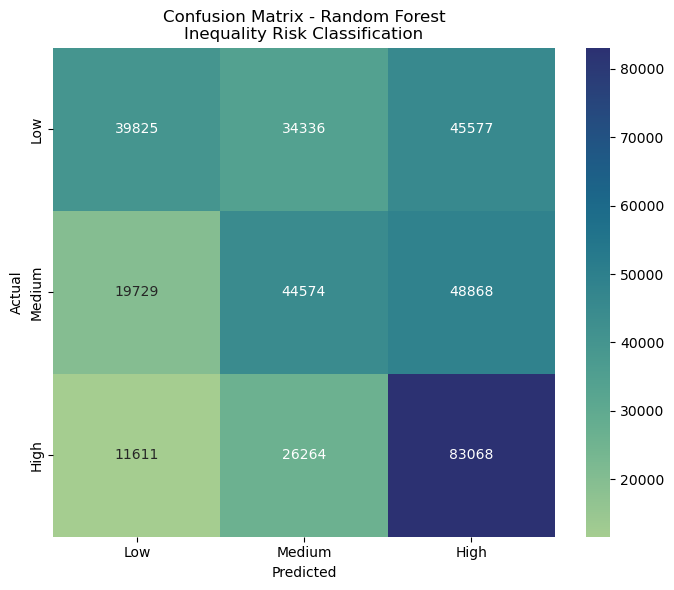

In [11]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize = (7,6))
sns.heatmap(cm, annot = True, fmt = 'd',cmap = 'crest',
            xticklabels = ['Low','Medium','High'],yticklabels = ['Low','Medium','High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest\nInequality Risk Classification')
plt.tight_layout()
plt.savefig('images/06_confusion_matrix.png', dpi=150)
plt.show()

#### ROC-AUC (One-vs-Rest, Since This Is a 3-Class Problem)

In [12]:
y_prob = rf.predict_proba(X_test)
auc = roc_auc_score(y_test,y_prob,multi_class = 'ovr', average = 'macro')
print(f'Macro ROC-AUC: {auc:.4f}')

Macro ROC-AUC: 0.6684


#### Optuna: Tuning the Strongest Candidate

In [ ]:
from sklearn.model_selection import cross_val_score

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400),
        'max_depth': trial.suggest_int('max_depth', 5, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
    }
    model = RandomForestClassifier(**params, random_state=42, n_jobs=-1)
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='accuracy', n_jobs=-1).mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=25)

print("Best params:", study.best_params)
print("Best CV accuracy:", study.best_value)

[I 2026-10-07 17:50:31,242] A new study created in memory with name: no-name-ad5f5433-f74a-4509-b0f9-2034560509ec


##### This runs 25 trials, each testing a different combination of Random Forest settings, using 3-fold cross-validation *within the training set only* to score each combination — the test set is never touched during this search.

#### Evaluating the Tuned Model

In [ ]:
best_rf = RandomForestClassifier(**study.best_params, random_state=42, n_jobs=-1)
best_rf.fit(X_train, y_train)
y_pred_tuned = best_rf.predict(X_test)

print(f"Tuned Test Accuracy: {accuracy_score(y_test, y_pred_tuned)*100:.2f}%")
print(f"Tuned Macro F1: {f1_score(y_test, y_pred_tuned, average='macro'):.4f}")

##### It applies the best parameters Optuna found to the actual held-out test set.
##### Optuna search as it is noticeably better than the untuned model appeared to be. But on the true chronological holdout (years 2020 onward, genuinely never seen during tuning), the tuned model actually scores slightly lower than the untuned default. A hyperparameter search optimized entirely on training-period cross-validation does not automatically transfer to genuinely future, unseen data — the two are not the same test. We retain the original, untuned Random Forest from Cell 8 as the final model for this module, since it performs at least as well on the evaluation that actually matters: real generalization to future years.

#### The Final Model

In [ ]:
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)
print(importance_df)